In [1]:

# =========================================
# COHORT ANALYSIS - DATA PREPARATION
# =========================================

import pandas as pd
import numpy as np
from pathlib import Path

# -----------------------------------------
# 1. Load Raw Dataset
# -----------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\abdal\OneDrive\Desktop\RetailSense_Customer_Analytics"
)

FILE_PATH = PROJECT_ROOT / "data" / "raw" / "Online Retail.xlsx"

if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {FILE_PATH}"
    )

df = pd.read_excel(FILE_PATH)

print("=" * 50)
print("COHORT ANALYSIS - DATA PREPARATION")
print("=" * 50)

print("\nOriginal Dataset Shape:", df.shape)


# -----------------------------------------
# 2. Validate Required Columns
# -----------------------------------------

required_columns = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID",
    "Country"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("\nRequired columns validation: PASSED")


# -----------------------------------------
# 3. Remove Exact Duplicates
# -----------------------------------------

original_rows = len(df)

df_clean = df.drop_duplicates().copy()

duplicates_removed = original_rows - len(df_clean)

print("\n--- Deduplication ---")
print("Rows After Deduplication:", len(df_clean))
print("Duplicates Removed:", duplicates_removed)


# -----------------------------------------
# 4. Data Type Validation
# -----------------------------------------

df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],
    errors="coerce"
)

# Identify invalid dates
invalid_dates = df_clean["InvoiceDate"].isna().sum()

# Remove rows with invalid dates
df_clean = df_clean[
    df_clean["InvoiceDate"].notna()
].copy()

print("\n--- Data Type Validation ---")
print("Invalid Invoice Dates Removed:", invalid_dates)


# -----------------------------------------
# 5. Prepare Valid Identified Purchases
# -----------------------------------------

# Exclude cancelled invoices
not_cancelled = ~df_clean[
    "InvoiceNo"
].astype(str).str.strip().str.upper().str.startswith("C")

# Keep positive quantities
positive_quantity = df_clean["Quantity"] > 0

# Keep positive unit prices
positive_price = df_clean["UnitPrice"] > 0

# Keep identified customers
identified_customers = df_clean["CustomerID"].notna()

# Combine all conditions
valid_purchase_mask = (
    not_cancelled
    & positive_quantity
    & positive_price
    & identified_customers
)

cohort_df = df_clean[
    valid_purchase_mask
].copy()


# -----------------------------------------
# 6. Clean CustomerID
# -----------------------------------------

cohort_df["CustomerID"] = (
    cohort_df["CustomerID"].astype("int64")
)


# -----------------------------------------
# 7. Calculate Purchase Revenue
# -----------------------------------------

cohort_df["Revenue"] = (
    cohort_df["Quantity"] * cohort_df["UnitPrice"]
)


# -----------------------------------------
# 8. Data Preparation Summary
# -----------------------------------------

print("\n--- Cohort Dataset Summary ---")

print("Cohort Dataset Shape:", cohort_df.shape)

print(
    "Unique Customers:",
    cohort_df["CustomerID"].nunique()
)

print(
    "Unique Invoices:",
    cohort_df["InvoiceNo"].nunique()
)

print(
    "Total Revenue:",
    f"£{cohort_df['Revenue'].sum():,.2f}"
)

print(
    "\nDate Range:",
    cohort_df["InvoiceDate"].min(),
    "to",
    cohort_df["InvoiceDate"].max()
)


# -----------------------------------------
# 9. Data Quality Checks
# -----------------------------------------

assert cohort_df["CustomerID"].notna().all(), \
    "Missing CustomerID found!"

assert (cohort_df["Quantity"] > 0).all(), \
    "Non-positive Quantity found!"

assert (cohort_df["UnitPrice"] > 0).all(), \
    "Non-positive UnitPrice found!"

assert not cohort_df[
    "InvoiceNo"
].astype(str).str.startswith("C").any(), \
    "Cancelled invoices found!"

assert cohort_df["InvoiceDate"].notna().all(), \
    "Invalid InvoiceDate found!"

print("\n" + "=" * 50)
print("DATA PREPARATION COMPLETED SUCCESSFULLY")
print("=" * 50)


COHORT ANALYSIS - DATA PREPARATION

Original Dataset Shape: (541909, 8)

Required columns validation: PASSED

--- Deduplication ---
Rows After Deduplication: 536641
Duplicates Removed: 5268

--- Data Type Validation ---
Invalid Invoice Dates Removed: 0

--- Cohort Dataset Summary ---
Cohort Dataset Shape: (392692, 9)
Unique Customers: 4338
Unique Invoices: 18532
Total Revenue: £8,887,208.89

Date Range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

DATA PREPARATION COMPLETED SUCCESSFULLY


In [2]:
# =========================================
# IDENTIFY CUSTOMER COHORT
# =========================================

# Transaction month
cohort_df["InvoiceMonth"] = (
    cohort_df["InvoiceDate"].dt.to_period("M")
)


# First purchase month for each customer
cohort_df["CohortMonth"] = (
    cohort_df.groupby("CustomerID")["InvoiceMonth"]
    .transform("min")
)

display(
    cohort_df[
        [
            "CustomerID",
            "InvoiceDate",
            "InvoiceMonth",
            "CohortMonth"
        ]
    ].head(10)
)

,CustomerID,InvoiceDate,InvoiceMonth,CohortMonth
0,17850,2010-12-01 08:26:00,2010-12,2010-12
1,17850,2010-12-01 08:26:00,2010-12,2010-12
2,17850,2010-12-01 08:26:00,2010-12,2010-12
3,17850,2010-12-01 08:26:00,2010-12,2010-12
4,17850,2010-12-01 08:26:00,2010-12,2010-12
5,17850,2010-12-01 08:26:00,2010-12,2010-12
6,17850,2010-12-01 08:26:00,2010-12,2010-12
7,17850,2010-12-01 08:28:00,2010-12,2010-12
8,17850,2010-12-01 08:28:00,2010-12,2010-12
9,13047,2010-12-01 08:34:00,2010-12,2010-12


In [3]:
# =========================================
# CALCULATE COHORT INDEX
# =========================================

cohort_df["CohortIndex"] = (
    (cohort_df["InvoiceMonth"].dt.year
     - cohort_df["CohortMonth"].dt.year) * 12

    + (cohort_df["InvoiceMonth"].dt.month
       - cohort_df["CohortMonth"].dt.month)
)

display(
    cohort_df[
        [
            "CustomerID",
            "InvoiceMonth",
            "CohortMonth",
            "CohortIndex"
        ]
    ].head(15)
)

,CustomerID,InvoiceMonth,CohortMonth,CohortIndex
0,17850,2010-12,2010-12,0
1,17850,2010-12,2010-12,0
2,17850,2010-12,2010-12,0
3,17850,2010-12,2010-12,0
4,17850,2010-12,2010-12,0
5,17850,2010-12,2010-12,0
6,17850,2010-12,2010-12,0
7,17850,2010-12,2010-12,0
8,17850,2010-12,2010-12,0
9,13047,2010-12,2010-12,0


In [4]:
# =========================================
# COHORT CUSTOMER COUNTS
# =========================================

cohort_counts = (
    cohort_df.groupby(
        ["CohortMonth", "CohortIndex"]
    )["CustomerID"]
    .nunique()
    .reset_index()
)

cohort_pivot = cohort_counts.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

# Keep 12 monthly periods
cohort_pivot = cohort_pivot.reindex(
    columns=range(12)
)

display(cohort_pivot)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# =========================================
# CALCULATE RETENTION RATE
# =========================================

cohort_sizes = cohort_pivot.iloc[:, 0]

retention_matrix = cohort_pivot.divide(
    cohort_sizes,
    axis=0
) * 100

retention_matrix = retention_matrix.round(2)

display(retention_matrix)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN


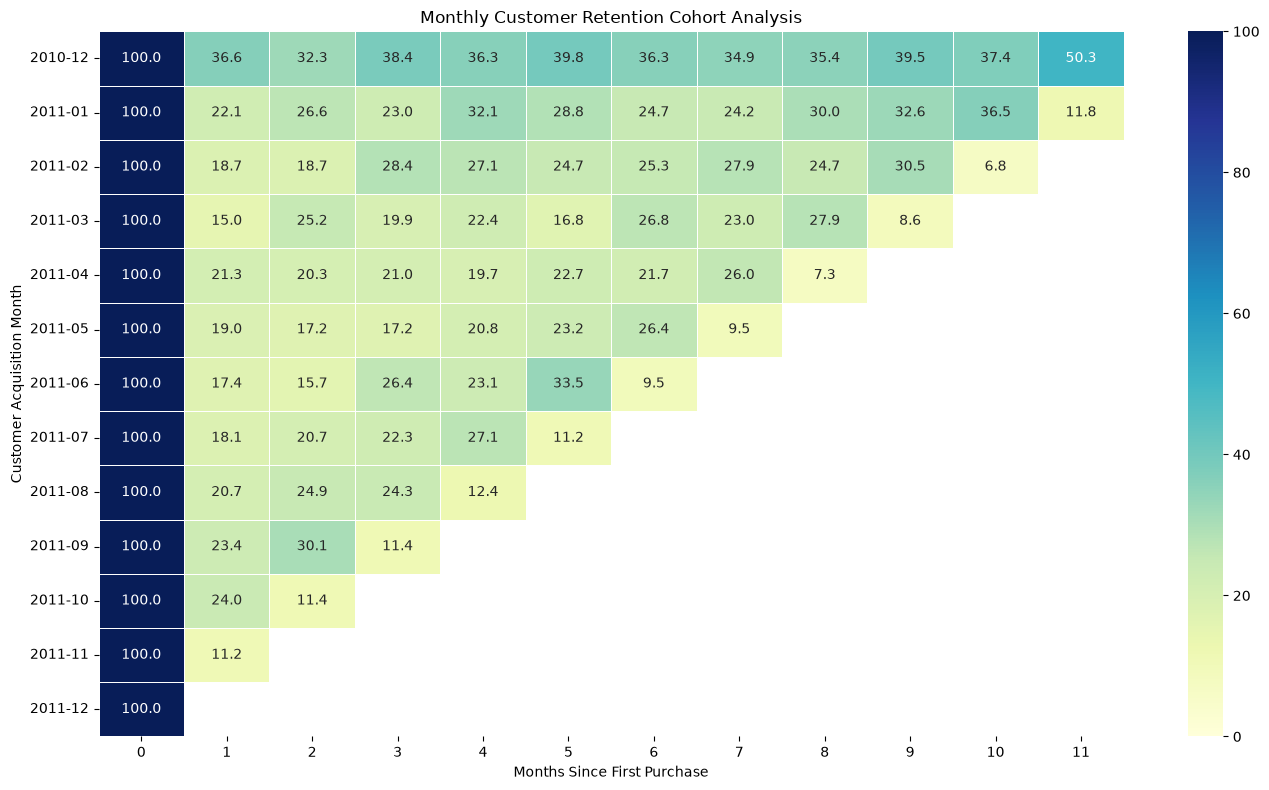

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title("Monthly Customer Retention Cohort Analysis")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Month")

plt.tight_layout()
plt.show()

## Cohort Analysis – Customer Retention

### Data Preparation
- Original Dataset: 541,909 rows.
- Rows after exact deduplication: 536,641.
- Duplicate rows removed: 5,268.
- Valid identified purchase records: 392,692.
- Unique customers: 4,338.
- Unique invoices: 18,532.

### Methodology
- Customers were grouped by their first purchase month.
- Monthly activity was calculated using distinct CustomerIDs.
- CohortIndex represents the number of months since the customer's first purchase.
- Monthly Retention Rate = Active Customers / Original Cohort Size × 100.

### Key Findings
- The December 2010 cohort started with 885 customers.
- Its Month 1 retention rate was 36.61%.
- Its Month 11 retention rate was 50.28%.
- Retention rates may increase between months because customers can return after periods of inactivity.
- Later cohorts have fewer observed months due to the dataset's end date of December 9, 2011.

### Important Considerations
- NaN values represent months that are not observable in the dataset, not zero retention.
- This analysis measures monthly customer activity, not continuous month-to-month retention.
- Only valid purchases with identified CustomerIDs were included.

In [7]:
print("Matrix Shape:", retention_matrix.shape)

print("\nMonth 0 Retention:")
print(retention_matrix[0].describe())

print("\nDecember 2010 Cohort:")
print(retention_matrix.loc[pd.Period("2010-12", freq="M")])

print("\nMissing Values:")
print(retention_matrix.isna().sum())

Matrix Shape: (13, 12)

Month 0 Retention:
count     13.0
mean     100.0
std        0.0
min      100.0
25%      100.0
50%      100.0
75%      100.0
max      100.0
Name: 0, dtype: float64

December 2010 Cohort:
CohortIndex
0     100.00
1      36.61
2      32.32
3      38.42
4      36.27
5      39.77
6      36.27
7      34.92
8      35.37
9      39.55
10     37.40
11     50.28
Name: 2010-12, dtype: float64

Missing Values:
CohortIndex
0      0
1      1
2      2
3      3
4      4
5      5
6      6
7      7
8      8
9      9
10    10
11    11
dtype: int64


In [8]:
monthly_retention = retention_matrix.mean(axis=0).round(2)

print("Average Retention by Month:")
display(monthly_retention.to_frame("Average Retention %"))

Average Retention by Month:


,Average Retention %
CohortIndex,
0,100.00
1,20.62
2,22.11
3,23.24
4,24.56
5,25.08
6,24.37
7,24.26
8,25.06


In [9]:
print("Maximum Cohort Index:", cohort_df["CohortIndex"].max())

print("\nCustomers by Cohort Index:")
display(
    cohort_df.groupby("CohortIndex")["CustomerID"]
    .nunique()
    .to_frame("Active Customers")
)

Maximum Cohort Index: 12

Customers by Cohort Index:


,Active Customers
CohortIndex,
0,4338
1,976
2,942
3,927
4,905
5,878
6,804
7,725
8,680


In [10]:
max_cohort_index = int(cohort_df["CohortIndex"].max())

cohort_pivot = (
    cohort_df.groupby(["CohortMonth", "CohortIndex"])["CustomerID"]
    .nunique()
    .unstack()
    .reindex(columns=range(max_cohort_index + 1))
)

cohort_sizes = cohort_pivot[0]

retention_matrix = (
    cohort_pivot.divide(cohort_sizes, axis=0) * 100
).round(2)

display(retention_matrix)

CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
cohort_observations = retention_matrix.notna().sum(axis=0)

cohort_summary = pd.DataFrame({
    "Available Cohorts": cohort_observations,
    "Average Retention %": retention_matrix.mean(axis=0).round(2)
})

display(cohort_summary)

,Available Cohorts,Average Retention %
CohortIndex,,
0,13,100.00
1,12,20.62
2,11,22.11
3,10,23.24
4,9,24.56
5,8,25.08
6,7,24.37
7,6,24.26
8,5,25.06


In [12]:
# 1. Total active customers in each month
active_customers = cohort_pivot.sum(axis=0, min_count=1)

# 2. Original cohort sizes
cohort_sizes = cohort_pivot[0]

# 3. Identify observable cohorts for each month
observed = cohort_pivot.notna()

# 4. Sum original cohort sizes only for observable cohorts
total_cohort_customers = observed.mul(
    cohort_sizes, axis=0
).sum(axis=0)

# 5. Calculate weighted retention
weighted_retention = (
    active_customers / total_cohort_customers * 100
).round(2)

# 6. Create comparison table
retention_comparison = pd.DataFrame({
    "Available Cohorts": observed.sum(axis=0),
    "Active Customers": active_customers,
    "Original Cohort Customers": total_cohort_customers,
    "Average Retention %": retention_matrix.mean(axis=0),
    "Weighted Retention %": weighted_retention
}).round(2)

display(retention_comparison)

,Available Cohorts,Active Customers,Original Cohort Customers,Average Retention %,Weighted Retention %
CohortIndex,,,,,
0,13,4338.0,4338.0,100.00,100.00
1,12,976.0,4297.0,20.62,22.71
2,11,942.0,3974.0,22.11,23.70
3,10,927.0,3616.0,23.24,25.64
4,9,905.0,3317.0,24.56,27.28
5,8,878.0,3148.0,25.08,27.89
6,7,804.0,2960.0,24.37,27.16
7,6,725.0,2718.0,24.26,26.67
8,5,680.0,2434.0,25.06,27.94


## Weighted Cohort Retention Analysis

### Methodology
Two retention metrics were calculated:

1. **Average Retention:** The arithmetic mean of retention percentages across all observable cohorts. Each cohort has equal weight.
2. **Weighted Retention:** Total active customers divided by the total original customers in all observable cohorts for each month.

### Key Findings
- Month 1 Weighted Retention: 22.71%.
- Month 3 Weighted Retention: 25.64%.
- Month 6 Weighted Retention: 27.16%.
- Month 9 Weighted Retention: 30.04%.
- Month 12 Weighted Retention: 26.55%.

### Interpretation
- Weighted retention is higher than unweighted average retention in most observed months.
- This indicates that larger cohorts generally contribute higher retention rates than the unweighted cohort average.
- Month 11 is based on only two observable cohorts.
- Month 12 is based on only one observable cohort.
- Later-month retention results should therefore be interpreted cautiously.
- Monthly retention measures customer activity in a particular month, not continuous month-to-month purchasing.

### Business Implications
- Monitor early repeat purchasing after customer acquisition.
- Compare cohorts using the same observation period.
- Use cohort retention alongside RFM segmentation to identify customers who may need re-engagement campaigns.

In [13]:
# 1. Cohort size
cohort_size_analysis = cohort_sizes.rename(
    "New Customers"
).to_frame()

# 2. Month-over-month change
cohort_size_analysis["MoM Change"] = (
    cohort_size_analysis["New Customers"].pct_change() * 100
).round(2)

# 3. Absolute change
cohort_size_analysis["Customer Change"] = (
    cohort_size_analysis["New Customers"].diff()
)

display(cohort_size_analysis.round(2))

,New Customers,MoM Change,Customer Change
CohortMonth,,,
2010-12,885.0,NaN,NaN
2011-01,417.0,-52.88,-468.0
2011-02,380.0,-8.87,-37.0
2011-03,452.0,18.95,72.0
2011-04,300.0,-33.63,-152.0
2011-05,284.0,-5.33,-16.0
2011-06,242.0,-14.79,-42.0
2011-07,188.0,-22.31,-54.0
2011-08,169.0,-10.11,-19.0


In [14]:
# Month 1 retention for each cohort
cohort_trend = pd.DataFrame({
    "Cohort Size": cohort_sizes,
    "Month 1 Retention": retention_matrix[1]
})

display(cohort_trend.round(2))

,Cohort Size,Month 1 Retention
CohortMonth,,
2010-12,885.0,36.61
2011-01,417.0,22.06
2011-02,380.0,18.68
2011-03,452.0,15.04
2011-04,300.0,21.33
2011-05,284.0,19.01
2011-06,242.0,17.36
2011-07,188.0,18.09
2011-08,169.0,20.71


In [15]:
# Exclude cohorts without Month 1 observations
correlation_data = cohort_trend.dropna()

correlation = correlation_data["Cohort Size"].corr(
    correlation_data["Month 1 Retention"]
)

print("Cohort Size vs Month 1 Retention Correlation:", round(correlation, 4))

Cohort Size vs Month 1 Retention Correlation: 0.7073


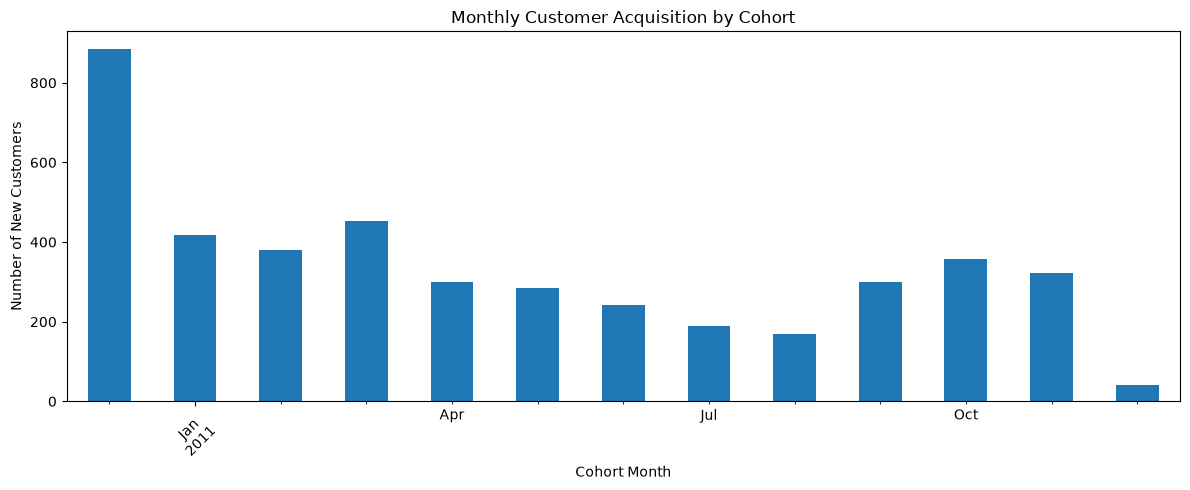

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

cohort_sizes.plot(kind="bar")

plt.title("Monthly Customer Acquisition by Cohort")
plt.xlabel("Cohort Month")
plt.ylabel("Number of New Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
from scipy.stats import pearsonr, spearmanr

# Exclude cohorts without Month 1 retention
correlation_data = cohort_trend.dropna()

# All available cohorts
pearson_all = pearsonr(
    correlation_data["Cohort Size"],
    correlation_data["Month 1 Retention"]
)

spearman_all = spearmanr(
    correlation_data["Cohort Size"],
    correlation_data["Month 1 Retention"]
)

# Sensitivity test: exclude December 2010
without_dec = correlation_data.iloc[1:]

pearson_without_dec = pearsonr(
    without_dec["Cohort Size"],
    without_dec["Month 1 Retention"]
)

spearman_without_dec = spearmanr(
    without_dec["Cohort Size"],
    without_dec["Month 1 Retention"]
)

print("All Cohorts:")
print("Pearson:", round(pearson_all.statistic, 4))
print("Spearman:", round(spearman_all.statistic, 4))

print("\nExcluding December 2010:")
print("Pearson:", round(pearson_without_dec.statistic, 4))
print("Spearman:", round(spearman_without_dec.statistic, 4))

All Cohorts:
Pearson: 0.7073
Spearman: 0.2448

Excluding December 2010:
Pearson: -0.0622
Spearman: 0.0182


### Correlation Sensitivity Analysis

Two correlation methods were used to examine the relationship between cohort size and Month 1 retention.

| Method | All Cohorts | Excluding December 2010 |
|---|---:|---:|
| Pearson | 0.7073 | -0.0622 |
| Spearman | 0.2448 | 0.0182 |

**Interpretation:**
- Pearson initially indicated a positive linear association.
- Spearman indicated a much weaker positive rank association.
- After excluding December 2010 as a sensitivity test, both correlations became close to zero.
- The initial positive Pearson correlation was strongly influenced by the December 2010 cohort.
- The analysis does not provide evidence of a stable relationship between cohort size and Month 1 retention.

**Final Decision:**
All cohorts are retained in the primary analysis. December 2010 is excluded only in the sensitivity test, not from the final dataset. No causal relationship is inferred from these observational results.

In [18]:
import pandas as pd

print("=== COHORT ANALYSIS DATAFRAMES ===")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print(f"Shape: {obj.shape}")
        print(f"Columns: {list(obj.columns)}")

=== COHORT ANALYSIS DATAFRAMES ===

Variable: df
Shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Variable: df_clean
Shape: (536641, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Variable: cohort_df
Shape: (392692, 12)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'InvoiceMonth', 'CohortMonth', 'CohortIndex']

Variable: cohort_counts
Shape: (91, 3)
Columns: ['CohortMonth', 'CohortIndex', 'CustomerID']

Variable: cohort_pivot
Shape: (13, 13)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Variable: retention_matrix
Shape: (13, 13)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Variable: cohort_summary
Shape: (13, 2)
Columns: ['Available Cohorts', 'Average Retention %']

Variable: observed
Shape: (13, 13)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 

In [19]:

# =========================================
# COHORT DATA INSPECTION
# =========================================

print("=== COHORT COUNTS ===")
display(cohort_counts.head(15))

print("\n=== COHORT PIVOT ===")
display(cohort_pivot)

print("\n=== RETENTION MATRIX ===")
display(
    retention_matrix.style.format("{:.2%}")
)

print("\n=== RETENTION MATRIX INFO ===")
print("Shape:", retention_matrix.shape)
print("Missing Values:", retention_matrix.isna().sum().sum())

print("\n=== RETENTION MATRIX DATA TYPES ===")
print(retention_matrix.dtypes)


=== COHORT COUNTS ===


,CohortMonth,CohortIndex,CustomerID
0,2010-12,0,885
1,2010-12,1,324
2,2010-12,2,286
3,2010-12,3,340
4,2010-12,4,321
5,2010-12,5,352
6,2010-12,6,321
7,2010-12,7,309
8,2010-12,8,313
9,2010-12,9,350



=== COHORT PIVOT ===


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== RETENTION MATRIX ===


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2010-12,10000.00%,3661.00%,3232.00%,3842.00%,3627.00%,3977.00%,3627.00%,3492.00%,3537.00%,3955.00%,3740.00%,5028.00%,2655.00%
2011-01,10000.00%,2206.00%,2662.00%,2302.00%,3213.00%,2878.00%,2470.00%,2422.00%,2998.00%,3261.00%,3645.00%,1175.00%,nan%
2011-02,10000.00%,1868.00%,1868.00%,2842.00%,2711.00%,2474.00%,2526.00%,2789.00%,2474.00%,3053.00%,684.00%,nan%,nan%
2011-03,10000.00%,1504.00%,2522.00%,1991.00%,2235.00%,1681.00%,2677.00%,2301.00%,2788.00%,863.00%,nan%,nan%,nan%
2011-04,10000.00%,2133.00%,2033.00%,2100.00%,1967.00%,2267.00%,2167.00%,2600.00%,733.00%,nan%,nan%,nan%,nan%
2011-05,10000.00%,1901.00%,1725.00%,1725.00%,2077.00%,2324.00%,2641.00%,951.00%,nan%,nan%,nan%,nan%,nan%
2011-06,10000.00%,1736.00%,1570.00%,2645.00%,2314.00%,3347.00%,950.00%,nan%,nan%,nan%,nan%,nan%,nan%
2011-07,10000.00%,1809.00%,2074.00%,2234.00%,2713.00%,1117.00%,nan%,nan%,nan%,nan%,nan%,nan%,nan%
2011-08,10000.00%,2071.00%,2485.00%,2426.00%,1243.00%,nan%,nan%,nan%,nan%,nan%,nan%,nan%,nan%



=== RETENTION MATRIX INFO ===
Shape: (13, 13)
Missing Values: 78

=== RETENTION MATRIX DATA TYPES ===
CohortIndex
0     float64
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
dtype: object


In [20]:
print(retention_matrix.head(4).to_string())
print("\nMinimum:", retention_matrix.min().min())
print("Maximum:", retention_matrix.max().max())

CohortIndex     0      1      2      3      4      5      6      7      8      9      10     11     12
CohortMonth                                                                                           
2010-12      100.0  36.61  32.32  38.42  36.27  39.77  36.27  34.92  35.37  39.55  37.40  50.28  26.55
2011-01      100.0  22.06  26.62  23.02  32.13  28.78  24.70  24.22  29.98  32.61  36.45  11.75    NaN
2011-02      100.0  18.68  18.68  28.42  27.11  24.74  25.26  27.89  24.74  30.53   6.84    NaN    NaN
2011-03      100.0  15.04  25.22  19.91  22.35  16.81  26.77  23.01  27.88   8.63    NaN    NaN    NaN

Minimum: 6.84
Maximum: 100.0


In [21]:

from pathlib import Path

# Create output folder
output_dir = Path("outputs/customer_view")
output_dir.mkdir(parents=True, exist_ok=True)

# Export cohort retention matrix
retention_matrix.to_csv(
    output_dir / "cohort_retention.csv",
    index=True,
    index_label="CohortMonth"
)

print("Cohort Retention Export Completed")
print("Shape:", retention_matrix.shape)
print("Saved to:", output_dir / "cohort_retention.csv")


Cohort Retention Export Completed
Shape: (13, 13)
Saved to: outputs\customer_view\cohort_retention.csv
